Results saved to /home/j-i15e104/inference_results/custom_images


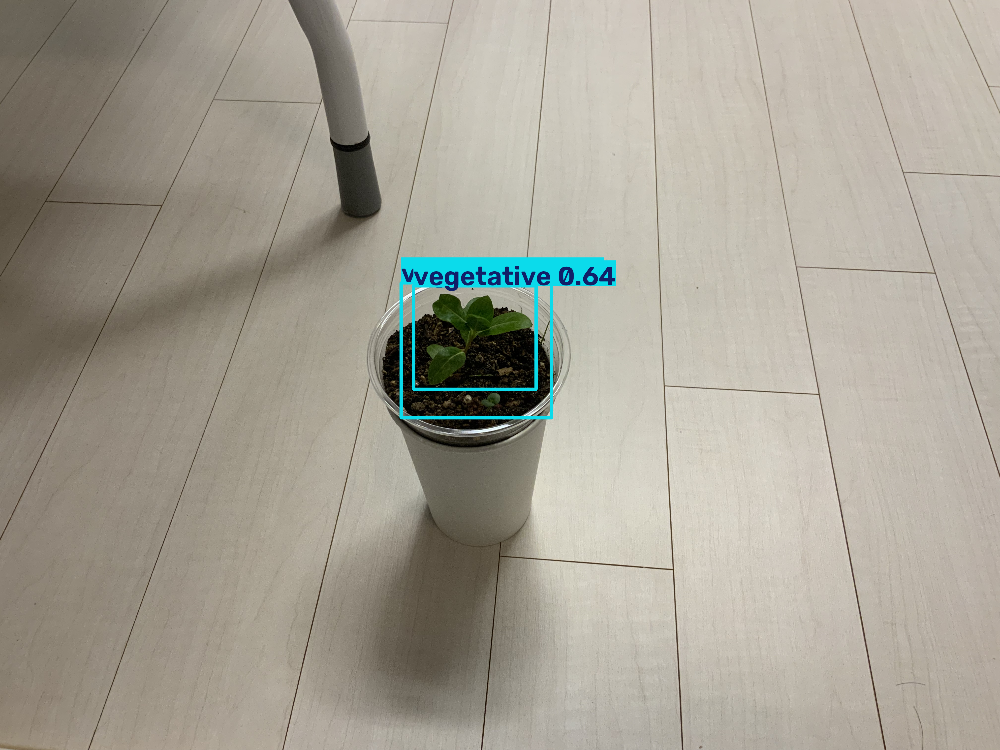

In [25]:
from pathlib import Path

from IPython.display import display
from PIL import Image
from ultralytics import YOLO

# 테스트할 이미지와 학습된 가중치 경로
IMAGE_PATH = Path("/home/j-i15e104/test_inputs/IMG_0051.HEIC")
WEIGHTS_PATH = Path("/home/j-i15e104/best.pt")

if not IMAGE_PATH.exists():
  raise FileNotFoundError(f"테스트 이미지를 찾을 수 없습니다: {IMAGE_PATH}")

if not WEIGHTS_PATH.exists():
  raise FileNotFoundError(f"학습 가중치를 찾을 수 없습니다: {WEIGHTS_PATH}")

# 가장 좋은 가중치 불러오기
inference_model = YOLO(str(WEIGHTS_PATH))

# GPU 4에서 추론
results = inference_model.predict(
  source=str(IMAGE_PATH),
  imgsz=640,
  conf=0.20,
  device=4,
  save=True,
  project="/home/j-i15e104/inference_results",
  name="custom_images",
  exist_ok=True,
  verbose=False,
)

# 바운딩 박스가 그려진 이미지 표시
for result in results:
  plotted_bgr = result.plot()
  plotted_rgb = plotted_bgr[..., ::-1]
  display(Image.fromarray(plotted_rgb))